# 02 — Preprocessing & Feature Engineering
## Smart Dormitory IoT Anomaly Detection

**Tujuan**: Menerapkan keputusan feature engineering dari EDA, melakukan encoding, scaling, dan temporal train/test split.

**Input**: `Smart_Dormitory_CLEAN_2025-11-01_to_2026-06-30.csv`, `feature_decisions.json`
**Output**: Data siap modeling — `X_train`, `X_test`, `y_test` (proxy labels), scaler objects.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
import sys
import json
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# === CONFIG ===
SEED = 42
DATA_PATH = "/content/Smart_Dormitory_CLEAN_2025-11-01_to_2026-06-30.csv"
OUTPUT_DIR = "/content/preprocessed"
FIGURE_DIR = "/content/figures"
TIMESTAMP_COL = "timestamp"

# Temporal split boundary
TRAIN_END = "2026-03-31 23:30:00"

# BiLSTM window size (from EDA: 48 steps = 24 hours)
WINDOW_SIZE = 48

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
Path(FIGURE_DIR).mkdir(parents=True, exist_ok=True)

# === Feature decisions (from 01_eda) ===
DROP_LEAKAGE = [
    "is_anomaly_proxy", "anomaly_severity_proxy",
    "command_active_alerts", "command_log_level",
    "command_event", "command_workflow",
]
DROP_CUMULATIVE = [
    "node03_energy_cumulative_kwh",
    "node04_water_cumulative_l",
]
DROP_REDUNDANT = [
    "node03_energy_interval_kwh",
    "node04_water_interval_l",
    "node03_current_a",
]
LABEL_COLS = ["is_anomaly_proxy", "anomaly_severity_proxy"]

STRONG_TEMPORAL = [
    "node01_temp_c", "node01_humidity_pct", "node02_temp_c",
    "node03_lux", "node04_flow_lpm", "node05_building_occupancy",
    "node05_entries_30m", "node06_toner_pct",
]
WEAK_TEMPORAL = [
    "node02_gas_raw", "node04_tank_level_pct", "node06_facility_power_w",
    "gateway_cpu_pct", "gateway_memory_pct", "packet_loss_pct",
]

print(f"Execution date: {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print(f"Python: {sys.version}")
print(f"numpy: {np.__version__}, pandas: {pd.__version__}")
print(f"\nColumns to drop: {len(DROP_LEAKAGE) + len(DROP_CUMULATIVE) + len(DROP_REDUNDANT)}")

Execution date: 2026-09-01 11:32
Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
numpy: 2.1.3, pandas: 2.2.3

Columns to drop: 11


### Load data & drop columns
**Tujuan**: Load dataset, simpan label untuk evaluasi, drop kolom leakage/cumulative/redundant.
**Input**: CSV dari `DATA_PATH`.
**Output**: `df` bersih tanpa kolom yang di-drop, `df_labels` berisi proxy labels.

In [6]:
df_raw = pd.read_csv(DATA_PATH, parse_dates=[TIMESTAMP_COL])

# Preserve labels for evaluation (not used in training)
df_labels = df_raw[[TIMESTAMP_COL, "is_anomaly_proxy", "anomaly_severity_proxy"]].copy()

# Recreate anomaly_tier from EDA
log_cols = [c for c in df_raw.columns if c.endswith("_log_level") and c != "command_log_level"]
critical_events = [
    "FIRE_EVENT_CONFIRMED", "LEAK_DETECTED_VALVE_CLOSED",
    "PANIC_BUTTON_ACTIVATED", "EMERGENCY_ACCESS_MODE",
    "RESTRICTED_AREA_INTRUSION", "VISUAL_FIRE_DETECTED",
]
event_cols = [c for c in df_raw.columns if c.endswith("_event") and c != "command_event"]

def classify_tier(row):
    for ec in event_cols:
        if row[ec] in critical_events:
            return "CRITICAL"
    n_warn = sum(1 for c in log_cols if row[c] != "INFO")
    if n_warn >= 2:
        return "MULTI_NODE_WARNING"
    if n_warn == 1:
        return "SINGLE_NODE_WARNING"
    return "NORMAL"

df_labels["anomaly_tier"] = df_raw.apply(classify_tier, axis=1)

# Drop columns
cols_to_drop = DROP_LEAKAGE + DROP_CUMULATIVE + DROP_REDUNDANT + ["interval_id"]
df = df_raw.drop(columns=cols_to_drop)

print(f"Raw shape: {df_raw.shape}")
print(f"After drop: {df.shape}")
print(f"Dropped {df_raw.shape[1] - df.shape[1]} columns")
print(f"\nLabels preserved: {df_labels.shape}")
print(f"Tier distribution:\n{df_labels['anomaly_tier'].value_counts()}")

# === Assertions ===
assert df.shape[0] == 11_616
assert df.shape[1] == 77 - len(cols_to_drop)
assert TIMESTAMP_COL in df.columns
for col in cols_to_drop:
    assert col not in df.columns, f"{col} still in df"
assert df_labels.shape[0] == df.shape[0]

print(f"\n✓ {df.shape[1]} columns retained, labels stored separately.")

Raw shape: (11616, 77)
After drop: (11616, 65)
Dropped 12 columns

Labels preserved: (11616, 4)
Tier distribution:
anomaly_tier
NORMAL                 6689
SINGLE_NODE_WARNING    4475
MULTI_NODE_WARNING      438
CRITICAL                 14
Name: count, dtype: int64

✓ 65 columns retained, labels stored separately.


### Classify remaining columns & encode categoricals
**Tujuan**: Memisahkan kolom numerik dan kategorikal, lalu melakukan encoding. Binary status (ON/OFF, OPEN/CLOSED) di-encode jadi 0/1. Log_level di-encode ordinal. Event columns di-drop karena redundant dengan log_level (event adalah deskripsi tekstual dari status yang sudah tercermin di fitur numerik + log_level).
**Input**: `df` (65 kolom).
**Output**: `df_encoded` — seluruh kolom numerik, siap scaling.

In [8]:
# Identify column types
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
string_cols = [c for c in df.select_dtypes(include=["object", "string"]).columns
               if c != TIMESTAMP_COL]

print(f"Numeric columns: {len(numeric_cols)}")
print(f"String columns:  {len(string_cols)}")
print(f"String columns list: {string_cols}")
print()

# === Encoding maps ===
binary_status_map = {
    "ON": 1, "OFF": 0,
    "OPEN": 1, "CLOSED": 0,
    "LOCKED": 1, "UNLOCKED": 0,
    "AVAILABLE": 1, "USED": 0,
    "RUNNING": 1,
    "READY": 1, "BUSY": 1, "TONER_LOW": 0,
    "CONNECTED": 1, "RECONNECTING": 0,
}

log_level_map = {"INFO": 0, "WARNING": 1, "CRITICAL": 2}

df_encoded = df.copy()

# 1. Binary status columns (including node02_siren, node02_emergency_light)
binary_cols_to_encode = [
    "node01_ac_status", "node01_fan_status",
    "node02_siren", "node02_emergency_light",
    "node03_light_status", "node03_outlet_status",
    "node04_pump_status", "node04_valve_status",
    "node05_door_status", "node05_lock_status", "node05_emergency_mode",
    "node06_locker01_status", "node06_locker02_status",
    "node06_laundry01_status", "node06_printer_status",
    "mqtt_status",
]

print("Binary encoding:")
for col in binary_cols_to_encode:
    unique_vals = list(df_encoded[col].unique())
    df_encoded[col] = df_encoded[col].map(binary_status_map)
    unmapped = df_encoded[col].isna().sum()
    print(f"  {col}: {unique_vals} -> binary | unmapped: {unmapped}")

print()

# 2. Log level columns (ordinal: INFO=0, WARNING=1, CRITICAL=2)
log_cols_encode = [c for c in string_cols if c.endswith("_log_level")]
print("Ordinal encoding (log_level):")
for col in log_cols_encode:
    df_encoded[col] = df_encoded[col].map(log_level_map)
    print(f"  {col}: INFO=0, WARNING=1, CRITICAL=2")

print()

# 3. Event columns — drop (redundant with log_level + numeric features)
event_cols_drop = [c for c in string_cols if c.endswith("_event")]
df_encoded = df_encoded.drop(columns=event_cols_drop)
print(f"Dropped {len(event_cols_drop)} event columns: {event_cols_drop}")

print(f"\nShape after encoding: {df_encoded.shape}")

# Verify no string columns remain (except timestamp)
remaining_strings = [c for c in df_encoded.select_dtypes(include=["object", "string"]).columns
                     if c != TIMESTAMP_COL]

# === Assertions ===
assert len(remaining_strings) == 0, f"String columns remain: {remaining_strings}"
assert df_encoded.isnull().sum().sum() == 0, f"NaN introduced during encoding"
assert df_encoded.shape[0] == 11_616

print(f"\n✓ All columns numeric. Final shape: {df_encoded.shape}")

Numeric columns: 34
String columns:  30
String columns list: ['node01_ac_status', 'node01_fan_status', 'node01_log_level', 'node01_event', 'node02_siren', 'node02_emergency_light', 'node02_log_level', 'node02_event', 'node03_light_status', 'node03_outlet_status', 'node03_log_level', 'node03_event', 'node04_pump_status', 'node04_valve_status', 'node04_log_level', 'node04_event', 'node05_door_status', 'node05_lock_status', 'node05_emergency_mode', 'node05_log_level', 'node05_event', 'node06_locker01_status', 'node06_locker02_status', 'node06_laundry01_status', 'node06_printer_status', 'node06_log_level', 'node06_event', 'cctv_log_level', 'cctv_event', 'mqtt_status']

Binary encoding:
  node01_ac_status: ['OFF', 'ON'] -> binary | unmapped: 0
  node01_fan_status: ['ON', 'OFF'] -> binary | unmapped: 0
  node02_siren: ['OFF', 'ON'] -> binary | unmapped: 0
  node02_emergency_light: ['OFF', 'ON'] -> binary | unmapped: 0
  node03_light_status: ['ON', 'OFF'] -> binary | unmapped: 0
  node03_outl

### Temporal feature engineering & scaling
**Tujuan**: Menambahkan fitur temporal (hour, dow) dengan cyclical encoding (sin/cos), lalu melakukan temporal train/test split dan scaling. Scaler di-fit hanya pada data training NORMAL.
**Input**: `df_encoded` (58 kolom).
**Output**: `X_train`, `X_test`, scaler objects, daftar fitur final.

In [9]:
# === 1. Temporal features ===
df_encoded["hour"] = df_encoded[TIMESTAMP_COL].dt.hour
df_encoded["dow"] = df_encoded[TIMESTAMP_COL].dt.dayofweek

# Cyclical encoding
df_encoded["hour_sin"] = np.sin(2 * np.pi * df_encoded["hour"] / 24)
df_encoded["hour_cos"] = np.cos(2 * np.pi * df_encoded["hour"] / 24)
df_encoded["dow_sin"] = np.sin(2 * np.pi * df_encoded["dow"] / 7)
df_encoded["dow_cos"] = np.cos(2 * np.pi * df_encoded["dow"] / 7)

# Drop raw hour/dow (keep only cyclical)
df_encoded = df_encoded.drop(columns=["hour", "dow"])

print(f"Shape after temporal features: {df_encoded.shape}")

# === 2. Define feature columns ===
feature_cols = [c for c in df_encoded.columns if c != TIMESTAMP_COL]
print(f"Feature columns: {len(feature_cols)}")

# === 3. Temporal train/test split ===
train_mask = df_encoded[TIMESTAMP_COL] <= TRAIN_END
test_mask = df_encoded[TIMESTAMP_COL] > TRAIN_END

df_train = df_encoded[train_mask].copy()
df_test = df_encoded[test_mask].copy()

# Labels aligned
labels_train = df_labels[train_mask].copy()
labels_test = df_labels[test_mask].copy()

print(f"\nTrain: {df_train.shape[0]} rows ({df_train[TIMESTAMP_COL].min()} — {df_train[TIMESTAMP_COL].max()})")
print(f"Test:  {df_test.shape[0]} rows ({df_test[TIMESTAMP_COL].min()} — {df_test[TIMESTAMP_COL].max()})")

# Anomaly distribution in splits
print(f"\nTrain anomaly rate: {labels_train['is_anomaly_proxy'].mean():.3f}")
print(f"Test anomaly rate:  {labels_test['is_anomaly_proxy'].mean():.3f}")
print(f"\nTrain tier distribution:")
print(labels_train["anomaly_tier"].value_counts())
print(f"\nTest tier distribution:")
print(labels_test["anomaly_tier"].value_counts())

# === 4. Identify NORMAL training data (for unsupervised fitting) ===
train_normal_mask = labels_train["anomaly_tier"] == "NORMAL"
df_train_normal = df_train[train_normal_mask.values]
print(f"\nTrain NORMAL only: {df_train_normal.shape[0]} rows (for scaler fitting)")

# === 5. Fit scalers on NORMAL training data only ===
scaler_standard = StandardScaler()
scaler_minmax = MinMaxScaler()

scaler_standard.fit(df_train_normal[feature_cols])
scaler_minmax.fit(df_train_normal[feature_cols])

# Transform all data
X_train_standard = pd.DataFrame(
    scaler_standard.transform(df_train[feature_cols]),
    columns=feature_cols, index=df_train.index
)
X_test_standard = pd.DataFrame(
    scaler_standard.transform(df_test[feature_cols]),
    columns=feature_cols, index=df_test.index
)

X_train_minmax = pd.DataFrame(
    scaler_minmax.transform(df_train[feature_cols]),
    columns=feature_cols, index=df_train.index
)
X_test_minmax = pd.DataFrame(
    scaler_minmax.transform(df_test[feature_cols]),
    columns=feature_cols, index=df_test.index
)

print(f"\nStandardScaler — train range: [{X_train_standard.min().min():.2f}, {X_train_standard.max().max():.2f}]")
print(f"MinMaxScaler   — train range: [{X_train_minmax.min().min():.2f}, {X_train_minmax.max().max():.2f}]")

# === Assertions ===
assert df_train.shape[0] + df_test.shape[0] == 11_616
assert len(feature_cols) == df_encoded.shape[1] - 1  # minus timestamp
assert X_train_standard.isnull().sum().sum() == 0
assert X_train_minmax.isnull().sum().sum() == 0
assert labels_train.shape[0] == df_train.shape[0]
assert labels_test.shape[0] == df_test.shape[0]

print(f"\n✓ Scaling complete. Features: {len(feature_cols)}")

Shape after temporal features: (11616, 62)
Feature columns: 61

Train: 7248 rows (2025-11-01 00:00:00 — 2026-03-31 23:30:00)
Test:  4368 rows (2026-04-01 00:00:00 — 2026-06-30 23:30:00)

Train anomaly rate: 0.421
Test anomaly rate:  0.431

Train tier distribution:
anomaly_tier
NORMAL                 4201
SINGLE_NODE_WARNING    2774
MULTI_NODE_WARNING      265
CRITICAL                  8
Name: count, dtype: int64

Test tier distribution:
anomaly_tier
NORMAL                 2488
SINGLE_NODE_WARNING    1701
MULTI_NODE_WARNING      173
CRITICAL                  6
Name: count, dtype: int64

Train NORMAL only: 4201 rows (for scaler fitting)

StandardScaler — train range: [-37.41, 29.91]
MinMaxScaler   — train range: [-1.00, 4.57]

✓ Scaling complete. Features: 61


### Create windowed sequences for BiLSTM-AE
**Tujuan**: Membuat sliding window sequences (window=48, 24 jam) dari data MinMax-scaled untuk input BiLSTM Autoencoder. Label per window ditentukan oleh label timestep terakhir dalam window.
**Input**: `X_train_minmax`, `X_test_minmax`, `labels_train`, `labels_test`.
**Output**: `X_train_seq`, `X_test_seq` (3D arrays), `y_test_seq` (labels per window).

In [10]:
def create_sequences(data, window_size):
    """Create sliding window sequences from 2D array.
    Returns 3D array of shape (n_samples - window_size + 1, window_size, n_features).
    """
    sequences = []
    for i in range(len(data) - window_size + 1):
        sequences.append(data[i : i + window_size])
    return np.array(sequences)

# === Training sequences (NORMAL only for unsupervised training) ===
train_normal_idx = labels_train[labels_train["anomaly_tier"] == "NORMAL"].index
X_train_normal_mm = X_train_minmax.loc[train_normal_idx]

# We need contiguous blocks for windowing — check for gaps
train_normal_positions = np.array([
    df_train.index.get_loc(idx) for idx in train_normal_idx
])
# Find contiguous blocks
gaps = np.where(np.diff(train_normal_positions) > 1)[0]
n_contiguous_blocks = len(gaps) + 1
print(f"NORMAL training data: {len(train_normal_idx)} rows in {n_contiguous_blocks} contiguous blocks")

# For simplicity and correctness: use ALL training data for sequencing,
# but filter sequences where the majority (>= 75%) of timesteps are NORMAL
X_train_all_arr = X_train_minmax.values
labels_train_arr = (labels_train["anomaly_tier"] == "NORMAL").values

X_train_seq_all = create_sequences(X_train_all_arr, WINDOW_SIZE)
labels_train_seq = []
for i in range(len(X_train_all_arr) - WINDOW_SIZE + 1):
    window_labels = labels_train_arr[i : i + WINDOW_SIZE]
    normal_ratio = window_labels.sum() / WINDOW_SIZE
    labels_train_seq.append(normal_ratio)

labels_train_seq = np.array(labels_train_seq)

# Keep only predominantly NORMAL windows (>= 75% normal timesteps)
normal_threshold = 0.75
normal_window_mask = labels_train_seq >= normal_threshold
X_train_seq = X_train_seq_all[normal_window_mask]

print(f"\nAll training windows: {X_train_seq_all.shape[0]}")
print(f"Predominantly NORMAL windows (>= {normal_threshold*100:.0f}%): {X_train_seq.shape[0]}")
print(f"Filtered out: {X_train_seq_all.shape[0] - X_train_seq.shape[0]}")

# === Test sequences (all data) ===
X_test_arr = X_test_minmax.values
X_test_seq = create_sequences(X_test_arr, WINDOW_SIZE)

# Label per window = label of LAST timestep
y_test_proxy = labels_test["is_anomaly_proxy"].values
y_test_tier = labels_test["anomaly_tier"].values

y_test_seq_proxy = y_test_proxy[WINDOW_SIZE - 1:]
y_test_seq_tier = y_test_tier[WINDOW_SIZE - 1:]

print(f"\nX_train_seq shape: {X_train_seq.shape}  (samples, window, features)")
print(f"X_test_seq shape:  {X_test_seq.shape}")
print(f"y_test_seq_proxy:  {y_test_seq_proxy.shape}")
print(f"y_test_seq_tier:   {y_test_seq_tier.shape}")

print(f"\nTest label distribution (windowed):")
unique, counts = np.unique(y_test_seq_tier, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  {u}: {c} ({c/len(y_test_seq_tier)*100:.1f}%)")

# === Assertions ===
assert X_train_seq.ndim == 3
assert X_test_seq.ndim == 3
assert X_train_seq.shape[1] == WINDOW_SIZE
assert X_train_seq.shape[2] == len(feature_cols)
assert X_test_seq.shape[0] == len(y_test_seq_proxy)
assert not np.isnan(X_train_seq).any()
assert not np.isnan(X_test_seq).any()

print(f"\n✓ Sequences created. Ready for modeling.")

NORMAL training data: 4201 rows in 654 contiguous blocks

All training windows: 7201
Predominantly NORMAL windows (>= 75%): 402
Filtered out: 6799

X_train_seq shape: (402, 48, 61)  (samples, window, features)
X_test_seq shape:  (4321, 48, 61)
y_test_seq_proxy:  (4321,)
y_test_seq_tier:   (4321,)

Test label distribution (windowed):
  CRITICAL: 6 (0.1%)
  NORMAL: 2488 (57.6%)

✓ Sequences created. Ready for modeling.


### Revised windowing strategy
**Tujuan**: Strategi sebelumnya terlalu ketat (75% normal threshold) menghasilkan hanya 402 sequences. Revisi: buat sequences dari seluruh training data, lalu gunakan label window terakhir untuk filtering. Model autoencoder belajar merekonstruksi pola — window yang mengandung sedikit anomali tetap berguna karena mayoritas timestep-nya normal.
**Input**: `X_train_minmax`, `X_test_minmax`.
**Output**: `X_train_seq` yang lebih besar, dengan strategi filtering yang lebih realistis.

In [11]:
# Strategy revision:
# - Use ALL training windows (7201) for autoencoder training
# - Autoencoder learns to reconstruct "typical" patterns
# - Since 57.9% of training data is NORMAL, the model will
#   learn normal patterns as the dominant mode
# - Anomalous windows will have higher reconstruction error
#   naturally, which is what we want to detect
#
# This is standard practice in unsupervised anomaly detection
# literature when anomalies are mixed into training data:
# the majority class dominates the learned representation.

# Alternative: filter by last-timestep label only
# (less aggressive than 75% window threshold)
last_step_normal = labels_train_arr[WINDOW_SIZE - 1:]  # True if NORMAL
X_train_seq_filtered = X_train_seq_all[last_step_normal]

print("=== Windowing strategy comparison ===")
print(f"Option A — All windows:              {X_train_seq_all.shape[0]}")
print(f"Option B — 75% normal threshold:     {X_train_seq.shape[0]}  (too few)")
print(f"Option C — Last-step normal only:    {X_train_seq_filtered.shape[0]}")
print()

# Go with Option C — reasonable balance
X_train_seq = X_train_seq_filtered

print(f"Selected: Option C (last-step normal)")
print(f"X_train_seq shape: {X_train_seq.shape}")
print(f"X_test_seq shape:  {X_test_seq.shape}")

# Also prepare flat arrays for MEWMA (no windowing needed)
X_train_mewma = X_train_standard.copy()
X_test_mewma = X_test_standard.copy()

# MEWMA trained on NORMAL data only
X_train_mewma_normal = X_train_mewma[labels_train["anomaly_tier"].values == "NORMAL"]

print(f"\nMEWMA data (StandardScaled, flat):")
print(f"  X_train_mewma_normal: {X_train_mewma_normal.shape}")
print(f"  X_test_mewma:         {X_test_mewma.shape}")

# === Assertions ===
assert X_train_seq.shape[0] > 1000, f"Still too few: {X_train_seq.shape[0]}"
assert X_train_seq.shape[1] == WINDOW_SIZE
assert X_train_seq.shape[2] == len(feature_cols)
assert X_train_mewma_normal.shape[1] == len(feature_cols)

print(f"\n✓ Revised windowing complete.")

=== Windowing strategy comparison ===
Option A — All windows:              7201
Option B — 75% normal threshold:     402  (too few)
Option C — Last-step normal only:    4160

Selected: Option C (last-step normal)
X_train_seq shape: (4160, 48, 61)
X_test_seq shape:  (4321, 48, 61)

MEWMA data (StandardScaled, flat):
  X_train_mewma_normal: (4201, 61)
  X_test_mewma:         (4368, 61)

✓ Revised windowing complete.


### Save preprocessed artifacts
**Tujuan**: Menyimpan semua data preprocessed, scaler, dan metadata agar notebook `03_mewma` dan `04_bilstm_ae` bisa langsung load tanpa mengulang preprocessing.
**Input**: Semua variabel preprocessed.
**Output**: File `.npz` dan `.pkl` di `OUTPUT_DIR`.

In [12]:
import pickle

# === 1. Save numpy arrays ===
np.savez_compressed(
    f"{OUTPUT_DIR}/sequences.npz",
    X_train_seq=X_train_seq,
    X_test_seq=X_test_seq,
    y_test_seq_proxy=y_test_seq_proxy,
    y_test_seq_tier=y_test_seq_tier,
)

# === 2. Save MEWMA data ===
X_train_mewma_normal.to_csv(f"{OUTPUT_DIR}/X_train_mewma_normal.csv", index=False)
X_test_mewma.to_csv(f"{OUTPUT_DIR}/X_test_mewma.csv", index=False)

# === 3. Save full test data with labels (for evaluation) ===
labels_test.to_csv(f"{OUTPUT_DIR}/labels_test.csv", index=False)
labels_train.to_csv(f"{OUTPUT_DIR}/labels_train.csv", index=False)

# === 4. Save scalers ===
with open(f"{OUTPUT_DIR}/scaler_standard.pkl", "wb") as f:
    pickle.dump(scaler_standard, f)
with open(f"{OUTPUT_DIR}/scaler_minmax.pkl", "wb") as f:
    pickle.dump(scaler_minmax, f)

# === 5. Save metadata ===
metadata = {
    "feature_cols": feature_cols,
    "window_size": WINDOW_SIZE,
    "train_end": TRAIN_END,
    "n_train_rows": df_train.shape[0],
    "n_test_rows": df_test.shape[0],
    "n_train_seq": X_train_seq.shape[0],
    "n_test_seq": X_test_seq.shape[0],
    "n_features": len(feature_cols),
    "strong_temporal": STRONG_TEMPORAL,
    "weak_temporal": WEAK_TEMPORAL,
}
with open(f"{OUTPUT_DIR}/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# === Verify saved files ===
saved_files = list(Path(OUTPUT_DIR).glob("*"))
print("Saved artifacts:")
for fp in sorted(saved_files):
    size_kb = fp.stat().st_size / 1024
    print(f"  {fp.name}: {size_kb:.1f} KB")

# === Assertions ===
assert Path(f"{OUTPUT_DIR}/sequences.npz").exists()
assert Path(f"{OUTPUT_DIR}/X_train_mewma_normal.csv").exists()
assert Path(f"{OUTPUT_DIR}/metadata.json").exists()

# Verify reload
test_load = np.load(f"{OUTPUT_DIR}/sequences.npz")
assert test_load["X_train_seq"].shape == X_train_seq.shape
assert test_load["X_test_seq"].shape == X_test_seq.shape

print(f"\n✓ All artifacts saved and verified in {OUTPUT_DIR}/")

Saved artifacts:
  X_test_mewma.csv: 3784.4 KB
  X_train_mewma_normal.csv: 3637.5 KB
  labels_test.csv: 179.1 KB
  labels_train.csv: 296.2 KB
  metadata.json: 2.0 KB
  scaler_minmax.pkl: 4.1 KB
  scaler_standard.pkl: 3.1 KB
  sequences.npz: 3414.4 KB

✓ All artifacts saved and verified in /content/preprocessed/


### PCA for MEWMA dimensionality reduction
**Tujuan**: Fit PCA pada data training NORMAL (StandardScaled) untuk mereduksi 61 fitur menjadi komponen utama. Jumlah komponen ditentukan oleh threshold 95% explained variance. PCA digunakan khusus untuk MEWMA layer — BiLSTM-AE tetap menggunakan semua 61 fitur.
**Input**: `X_train_mewma_normal`.
**Output**: PCA model, transformed data, scree plot.

=== PCA explained variance ===
  90% variance: 23 components
  95% variance: 27 components
  99% variance: 33 components
  Total components: 61

Selected: 27 components (95.9% variance)
X_train_pca: (4201, 27)
X_test_pca:  (4368, 27)


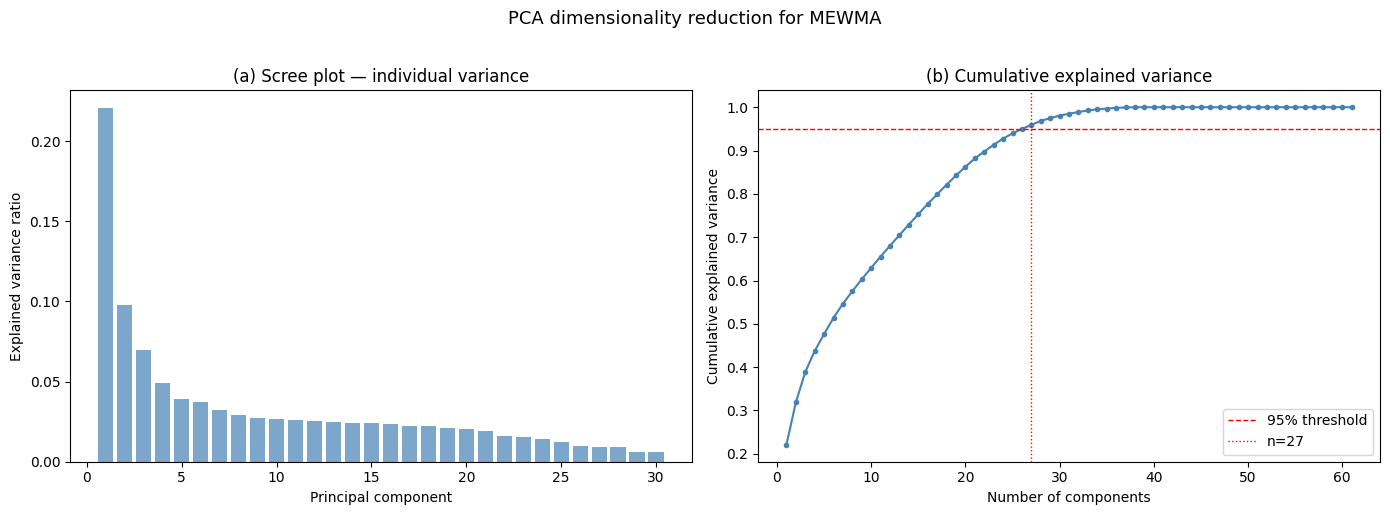


=== Top 3 feature loadings per component ===
  PC1 (22.1%): node01_temp_c(+0.296), hour_cos(-0.288), node03_light_status(-0.288)
  PC2 (9.8%): node03_power_w(+0.310), node05_entries_30m(+0.295), node06_study_room_occupancy(+0.288)
  PC3 (7.0%): node05_door_status(+0.361), node05_lock_status(-0.361), node01_ac_status(-0.344)
  PC4 (4.9%): node06_study_room_occupancy(+0.443), hour_sin(-0.404), node01_ac_status(-0.309)
  PC5 (3.9%): mqtt_status(+0.693), packet_loss_pct(-0.691), node04_pump_status(+0.108)

✓ PCA complete. 27 components saved.


In [13]:
from sklearn.decomposition import PCA

# Fit PCA on NORMAL training data (already StandardScaled)
pca_full = PCA(random_state=SEED)
pca_full.fit(X_train_mewma_normal.values)

# Determine n_components at 95% explained variance
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = np.argmax(cumvar >= 0.95) + 1
n_components_90 = np.argmax(cumvar >= 0.90) + 1
n_components_99 = np.argmax(cumvar >= 0.99) + 1

print("=== PCA explained variance ===")
print(f"  90% variance: {n_components_90} components")
print(f"  95% variance: {n_components_95} components")
print(f"  99% variance: {n_components_99} components")
print(f"  Total components: {len(cumvar)}")
print()

# Use 95% threshold
N_PCA = n_components_95
pca = PCA(n_components=N_PCA, random_state=SEED)
pca.fit(X_train_mewma_normal.values)

# Transform
X_train_pca = pca.transform(X_train_mewma_normal.values)
X_test_pca = pca.transform(X_test_mewma.values)

print(f"Selected: {N_PCA} components ({cumvar[N_PCA-1]*100:.1f}% variance)")
print(f"X_train_pca: {X_train_pca.shape}")
print(f"X_test_pca:  {X_test_pca.shape}")

# Scree plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.bar(range(1, min(31, len(cumvar)+1)),
        pca_full.explained_variance_ratio_[:30],
        alpha=0.7, color="steelblue", label="Individual")
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Explained variance ratio")
ax1.set_title("(a) Scree plot — individual variance")

ax2.plot(range(1, len(cumvar)+1), cumvar, "o-", markersize=3, color="steelblue")
ax2.axhline(y=0.95, color="red", linestyle="--", linewidth=1, label="95% threshold")
ax2.axvline(x=N_PCA, color="red", linestyle=":", linewidth=1, label=f"n={N_PCA}")
ax2.set_xlabel("Number of components")
ax2.set_ylabel("Cumulative explained variance")
ax2.set_title("(b) Cumulative explained variance")
ax2.legend()

fig.suptitle("PCA dimensionality reduction for MEWMA", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(f"{FIGURE_DIR}/fig_07_pca_scree.png", bbox_inches="tight")
plt.show()

# Top feature loadings for first 5 PCs
print("\n=== Top 3 feature loadings per component ===")
for i in range(min(5, N_PCA)):
    loadings = pd.Series(pca.components_[i], index=feature_cols)
    top = loadings.abs().nlargest(3)
    top_str = ", ".join([f"{feat}({loadings[feat]:+.3f})" for feat in top.index])
    var_pct = pca.explained_variance_ratio_[i] * 100
    print(f"  PC{i+1} ({var_pct:.1f}%): {top_str}")

# Save PCA artifacts
np.savez_compressed(
    f"{OUTPUT_DIR}/pca_data.npz",
    X_train_pca=X_train_pca,
    X_test_pca=X_test_pca,
)
with open(f"{OUTPUT_DIR}/pca_model.pkl", "wb") as f:
    pickle.dump(pca, f)

# === Assertions ===
assert X_train_pca.shape == (X_train_mewma_normal.shape[0], N_PCA)
assert X_test_pca.shape == (X_test_mewma.shape[0], N_PCA)
assert not np.isnan(X_train_pca).any()
assert not np.isnan(X_test_pca).any()

print(f"\n✓ PCA complete. {N_PCA} components saved.")